# pRF comparison AE / FE / controls with an ocular-dominance filter

Same analyses as the prf_analysis scripts `make_ecc_comp`, `make_ecc_size_pcm` and `make_active_vert` (same thresholds, same eye labels, same group aggregation, same statistics, same plotting functions), with one addition: an **ocular-dominance (OD) filter**.

**OD filter.** For each vertex, OD index `(β_L − β_R) / (β_L + β_R)` from the OD image of `make_od_img.py` (common pRF regressor, 4 runs; defined where both betas are > 0, i.e. > 99.5 % of the vertices). Each eye only keeps the vertices that **prefer it**:

| group | eye condition | vertices kept |
|---|---|---|
| amblyopes | AE-RE (amblyopic eye) | OD toward the amblyopic eye > 0 |
| amblyopes | FE-LE (fellow eye) | OD toward the fellow eye > 0 |
| controls | AE-RE (right eye) | OD < 0 (prefer the right eye) |
| controls | FE-LE (left eye) | OD > 0 (prefer the left eye) |
| controls | CTRL | median of RE and LE (as in the scripts) |

**Data.** Everything comes from the PSC prfmodel pipeline, the same as the OD: pRF derivatives, fit statistics and pCM of each eye (`prfmodel/prf_derivatives`, task BarsBarsRingsWedges, concat), ROIs `rois-group-mmp` (as the prf_analysis figures). The vertex data are cached locally in `Desktop/fig_od/prf_od_filter_cache/` (rebuilt automatically when a source file is newer).

**Two versions of every measure:** `filter = 'none'` (same as the prf_analysis scripts, on the PSC data) and `filter = 'od'` (OD filter). The figures show the OD-filtered version; the no-filter version is kept for comparison.

**What changes with the filter.** Without filter, both eyes are described on (almost) the same vertices. With the filter, each eye is described on **its own** vertices: the comparison AE vs FE becomes "the cortex that prefers the AE" vs "the cortex that prefers the FE". In amblyopes, the AE keeps fewer vertices (30-40 % of the cortex prefers it, Figure 1 of the OD analysis), and these vertices may differ in eccentricity or ROI position from those of the FE: differences in pRF size or pCM can then come from **where** these vertices are, not only from the eye. The number of vertices and the eccentricity of each set are therefore reported.

Nothing is written in the data folders; figures go to `Desktop/fig_od` (prefix `prf_od-filter_`).

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

import os
import sys
import numpy as np
import pandas as pd
from scipy import stats

# Personal imports: prf_analysis utils (plots of amblyo7T_prf first, then the general utils)
sys.path.insert(0, "{}/../utils".format(os.getcwd()))
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from plot_utils import ecc_comp_plot, eyes_ecc_size_pcm_plot, eyes_active_vert_plot
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex
from maths_utils import weighted_nan_median, weighted_nan_percentile

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
vcache_dir = '{}/prf_od_filter_cache'.format(fig_dir)
os.makedirs(vcache_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients, controls = analysis_info['group-patient'], analysis_info['group-control']
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_pcm = analysis_info['maps_names_pcm']
maps_names_css_od = analysis_info['maps_names_css_od']

# Analysis (as the prf_analysis scripts, PSC)
normalization = 'psc'
task = 'BarsBarsRingsWedges'
rois_method = 'rois-group-mmp'
rois = list(analysis_info[rois_method].keys())
rois_to_plot = analysis_info['rois_to_plot']                    # 'roi_mmp'
rsq2use = 'prf_rsq'
ecc_th, size_th, n_th = analysis_info['ecc_th'], analysis_info['size_th'], analysis_info['n_th']
rsqr_th, stats_th = analysis_info['rsqr_th'], analysis_info['stats_th']
amp_th = analysis_info['prf_amp_th'][normalization]
stats_col = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'
foveal_bound = analysis_info['foveal_ecc_bound']
params = analysis_info['ecc_comp_params']                       # prf_rsq, prf_size, prf_ecc, pcm_median, prf_n
ecc_categories = ['all', 'foveal', 'peripheral']
ecc_size_bins = analysis_info['ecc_size_max'][0] * (np.linspace(0, 1, analysis_info['ecc_size_num_bins'] + 1) ** analysis_info['ecc_bin_power'])
ecc_pcm_bins = analysis_info['ecc_pcm_max'][0] * (np.linspace(0, 1, analysis_info['ecc_pcm_num_bins'] + 1) ** analysis_info['ecc_bin_power'])
filters = ['none', 'od']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}
fspec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}_hemi-{}_fmriprep_dct_psc_concat_{}.func.gii'

# Participants: amblyopic eye
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e)[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)}

# Pycortex database (ROIs)
set_pycortex_config_file('{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir))

## Vertex data (local cache)

Per subject, vertices of the 8 ROIs only: pRF derivatives, fit statistics and pCM of each eye, ROI label, betas of both eyes on the common regressor (OD image). Read once from the data disks, then from `prf_od_filter_cache/`.

In [3]:
def source_files(subject):
    fns = {'od': [fspec.format(pp_dir, subject, subject, task, h, 'prf-css_od') for h in 'LR']}
    for e, eye in eyes.items():
        fns['deriv_' + e] = [fspec.format(pp_dir, subject, subject, task + eye, h, 'prf-css_deriv') for h in 'LR']
        fns['stats_' + e] = [fspec.format(pp_dir, subject, subject, task + eye, h, 'prf-css_stats') for h in 'LR']
        fns['pcm_' + e] = [fspec.format(pp_dir, subject, subject, task + eye, h, '{}_prf-css_pcm'.format(rois_method)) for h in 'LR']
    return fns


def load_subject(subject):
    """DataFrame of the ROI vertices of one subject (one row per vertex), from the local cache when up to date."""
    fns = source_files(subject)
    all_fns = [f for v in fns.values() for f in v]
    if not all(os.path.isfile(f) for f in all_fns):
        return None
    cache_fn = '{}/{}_prf-od-filter-cache.tsv.gz'.format(vcache_dir, subject)
    src_mtime = max(os.path.getmtime(f) for f in all_fns)
    if os.path.isfile(cache_fn) and os.path.getmtime(cache_fn) >= src_mtime:
        return pd.read_csv(cache_fn, sep='\t')
    roi_masks = get_rois(subject=subject, surf_format='fsnative', rois_type=rois_method, mask=True, rois=None, hemis=None)
    od = load_surface_pycortex(L_fn=fns['od'][0], R_fn=fns['od'][1], return_hemi_len=True)
    n_l = od['len_L']
    label = np.full(od['data_concat'].shape[1], '', dtype=object)
    for roi in rois:
        label[roi_masks[roi]] = roi
    idx = np.where(label != '')[0]
    df = pd.DataFrame({'vertex': idx, 'hemi': np.where(idx < n_l, 'hemi-L', 'hemi-R'), rois_to_plot: label[idx],
                       'beta_L': od['data_concat'][maps_names_css_od.index('od_beta_le')][idx],
                       'beta_R': od['data_concat'][maps_names_css_od.index('od_beta_re')][idx]})
    for e in eyes:
        for kind, names in [('deriv', maps_names_css), ('stats', maps_names_css_stats), ('pcm', maps_names_pcm)]:
            mat = load_surface_pycortex(L_fn=fns['{}_{}'.format(kind, e)][0], R_fn=fns['{}_{}'.format(kind, e)][1])['data_concat']
            for i, name in enumerate(names):
                df['{}_{}'.format(name, e)] = mat[i][idx]
    df.to_csv(cache_fn, sep='\t', index=False)
    print('{}: read from the data disks, cached'.format(subject), end=' | ')
    return df


vertex_data = {}
for subject in patients + controls:
    d = load_subject(subject)
    if d is None:
        print('{}: files missing, skipped'.format(subject))
        continue
    vertex_data[subject] = d
    print('{}: {} ROI vertices'.format(subject, len(d)))

sub-01: read from the data disks, cached | sub-01: 29401 ROI vertices
sub-02: read from the data disks, cached | sub-02: 26088 ROI vertices
sub-03: read from the data disks, cached | sub-03: 33991 ROI vertices
sub-04: read from the data disks, cached | sub-04: 22556 ROI vertices
sub-05: read from the data disks, cached | sub-05: 26814 ROI vertices
sub-06: read from the data disks, cached | sub-06: 34128 ROI vertices
sub-07: read from the data disks, cached | sub-07: 26788 ROI vertices
sub-08: read from the data disks, cached | sub-08: 36097 ROI vertices
sub-09: read from the data disks, cached | sub-09: 27641 ROI vertices
sub-10: read from the data disks, cached | sub-10: 32839 ROI vertices
sub-11: read from the data disks, cached | sub-11: 30854 ROI vertices
sub-12: read from the data disks, cached | sub-12: 27215 ROI vertices
sub-13: read from the data disks, cached | sub-13: 29751 ROI vertices
sub-14: read from the data disks, cached | sub-14: 31633 ROI vertices
sub-16: read from th

## Per-subject measures (as the prf_analysis scripts)

For each subject, eye and filter:

1. **Eye label** as the scripts: amblyopes AE-RE = amblyopic eye, FE-LE = fellow eye; controls AE-RE = right eye, FE-LE = left eye.
2. **OD filter** (`filter = 'od'`): vertices with OD toward this eye > 0 (both betas > 0).
3. **ecc-comp** (`make_ecc_comp_tsv.py`): thresholds of the scripts (amplitude ≥ min, eccentricity, size, n, R², fit p-value), then per ROI × eccentricity category (all, foveal ≤ 2.5°, peripheral): R²-weighted median and 25-75 % of pRF R², size, eccentricity, pCM, n, and the number of vertices; controls: CTRL = median of RE and LE.
4. **ecc-size / ecc-pCM** (`make_ecc_size_pcm_tsv.py`): same thresholds, eccentricity bins (power spacing), R²-weighted median of size and pCM per bin; controls: CTRL.
5. **Active vertices** (`make_active_vert_tsv.py`): no threshold; per ROI, number of vertices with fit p (FDR) < 0.05 and < 0.01 **among the vertices that prefer this eye** (filter `od`) or all (filter `none`), and their proportion of the ROI.

In [4]:
def eye_condition(subject, e):
    if subject in patients:
        return 'AE-RE' if e == ambly_eye[subject] else 'FE-LE'
    return 'AE-RE' if e == 'R' else 'FE-LE'


def eye_table(d, e, filt):
    """Vertices of one eye as a table with the column names of the prf-css-deriv.tsv files; OD filter if filt == 'od'."""
    o = 'R' if e == 'L' else 'L'
    t = pd.DataFrame({rois_to_plot: d[rois_to_plot], 'hemi': d['hemi']})
    for name in maps_names_css + maps_names_css_stats + maps_names_pcm:
        t[name] = d['{}_{}'.format(name, e)]
    b_e, b_o = d['beta_{}'.format(e)], d['beta_{}'.format(o)]
    with np.errstate(divide='ignore', invalid='ignore'):
        t['od_eye'] = np.where((b_e > 0) & (b_o > 0), (b_e - b_o) / (b_e + b_o), np.nan)    # OD toward this eye
    if filt == 'od':
        t = t[t.od_eye > 0]
    return t


def threshold(t):
    """Thresholds of make_ecc_comp_tsv.py / make_ecc_size_pcm_tsv.py."""
    bad = ((t.amplitude < amp_th[0]) | (t.prf_ecc < ecc_th[0]) | (t.prf_ecc > ecc_th[1]) | (t.prf_size < size_th[0])
           | (t.prf_size > size_th[1]) | (t.prf_n < n_th[0]) | (t.prf_n > n_th[1]) | (t[rsq2use] < rsqr_th) | (t[stats_col] > stats_th))
    return t[~bad].dropna(subset=['prf_ecc', 'prf_size', rsq2use, 'pcm_median', 'prf_n'])


def wq(x, w, q):
    return weighted_nan_percentile(np.asarray(x, float), np.asarray(w, float), q) if len(x) else np.nan


def wmed(x, w):
    return weighted_nan_median(np.asarray(x, float), np.asarray(w, float)) if len(x) else np.nan


ecc_rows, size_rows, act_rows = [], [], []
for subject, d in vertex_data.items():
    group = 'patient' if subject in patients else 'control'
    for filt in filters:
        sub_ecc, sub_size, sub_act = [], [], []
        for e in eyes:
            cond = eye_condition(subject, e)
            t_raw = eye_table(d, e, filt)
            # active vertices (no threshold; denominator = all ROI vertices)
            for roi in rois:
                n_tot = np.sum(d[rois_to_plot] == roi)
                tr = t_raw[t_raw[rois_to_plot] == roi]
                n5, n1 = np.sum(tr.corr_pvalue_5pt < 0.05), np.sum(tr.corr_pvalue_1pt < 0.01)
                sub_act.append({'subject': subject, 'subject_group': group, 'filter': filt, rois_to_plot: roi, 'eye_condition': cond,
                                'n_vert_tot': n_tot, 'n_vert_corr_pvalue_5pt': n5, 'n_vert_corr_pvalue_1pt': n1,
                                'ratio_5pt': n5 / n_tot if n_tot else np.nan, 'ratio_1pt': n1 / n_tot if n_tot else np.nan})
            t = threshold(t_raw)
            for roi in rois:
                tr = t[t[rois_to_plot] == roi]
                # ecc-comp
                for cat in ecc_categories:
                    tc = tr if cat == 'all' else (tr[tr.prf_ecc <= foveal_bound] if cat == 'foveal' else tr[tr.prf_ecc > foveal_bound])
                    w = tc[rsq2use].values
                    row = {'subject': subject, 'subject_group': group, 'filter': filt, rois_to_plot: roi, 'eye_condition': cond,
                           'ecc_category': cat, 'n_vert': len(tc)}
                    for p in params:
                        row['{}_median'.format(p)] = wmed(tc[p].values, w)
                        row['{}_ci_lo'.format(p)] = wq(tc[p].values, w, 25)
                        row['{}_ci_hi'.format(p)] = wq(tc[p].values, w, 75)
                    sub_ecc.append(row)
                # ecc-size / ecc-pcm
                for b in range(len(ecc_size_bins) - 1):
                    ts = tr[(tr.prf_ecc > ecc_size_bins[b]) & (tr.prf_ecc <= ecc_size_bins[b + 1])]
                    tp = tr[(tr.prf_ecc > ecc_pcm_bins[b]) & (tr.prf_ecc <= ecc_pcm_bins[b + 1])]
                    ws, wp = ts[rsq2use].values, tp[rsq2use].values
                    sub_size.append({'subject': subject, 'subject_group': group, 'filter': filt, 'roi': roi, 'eye_condition': cond, 'num_bins': b,
                                     'prf_ecc_bins': wmed(ts.prf_ecc.values, ws),
                                     'prf_size_bins_median': wmed(ts.prf_size.values, ws),
                                     'prf_size_bins_ci_upper_bound': wq(ts.prf_size.values, ws, 75),
                                     'prf_size_bins_ci_lower_bound': wq(ts.prf_size.values, ws, 25),
                                     '{}_bins_median'.format(rsq2use): wmed(ts[rsq2use].values, ws),
                                     '{}_bins_ci_upper_bound'.format(rsq2use): wq(ts[rsq2use].values, ws, 75),
                                     '{}_bins_ci_lower_bound'.format(rsq2use): wq(ts[rsq2use].values, ws, 25),
                                     'n_vert_bins': len(ts),
                                     'prf_pcm_bins_median': wmed(tp.pcm_median.values, wp),
                                     'prf_pcm_bins_ci_upper_bound': wq(tp.pcm_median.values, wp, 75),
                                     'prf_pcm_bins_ci_lower_bound': wq(tp.pcm_median.values, wp, 25)})
        sub_ecc, sub_size = pd.DataFrame(sub_ecc), pd.DataFrame(sub_size)
        # controls: CTRL = median of RE and LE (as the scripts)
        if group == 'control':
            vals = [c for c in sub_ecc.columns if c.endswith('_median')] + ['n_vert']
            ctrl = sub_ecc.groupby([rois_to_plot, 'ecc_category'])[vals].median().reset_index()
            ctrl = ctrl.assign(subject=subject, subject_group=group, filter=filt, eye_condition='CTRL')
            sub_ecc = pd.concat([sub_ecc, ctrl], ignore_index=True)
            vals = [c for c in sub_size.columns if c not in ['subject', 'subject_group', 'filter', 'roi', 'eye_condition', 'num_bins']]
            ctrl = sub_size.groupby(['roi', 'num_bins'])[vals].median().reset_index()
            ctrl = ctrl.assign(subject=subject, subject_group=group, filter=filt, eye_condition='CTRL')
            sub_size = pd.concat([sub_size, ctrl], ignore_index=True)
        ecc_rows.append(sub_ecc); size_rows.append(sub_size); act_rows.append(pd.DataFrame(sub_act))
    print('{}: done'.format(subject))
df_ecc = pd.concat(ecc_rows, ignore_index=True)
df_size = pd.concat(size_rows, ignore_index=True)
df_act = pd.concat(act_rows, ignore_index=True)

# Number of vertices kept per eye (all eccentricities): median across subjects
print('\nThresholded vertices per ROI (median across subjects), no filter vs OD filter:')
nv = df_ecc[df_ecc.ecc_category == 'all'].groupby(['subject_group', 'eye_condition', 'filter', rois_to_plot]).n_vert.median()
print(nv.unstack(rois_to_plot)[rois].round(0).to_string())

sub-01: done
sub-02: done
sub-03: done
sub-04: done
sub-05: done
sub-06: done
sub-07: done
sub-08: done
sub-09: done
sub-10: done
sub-11: done
sub-12: done
sub-13: done
sub-14: done
sub-16: done
sub-17: done
sub-18: done
sub-19: done
sub-20: done

Thresholded vertices per ROI (median across subjects), no filter vs OD filter:
roi_mmp                                 V1      V2      V3      V4     V3A    V3B    LO1    LO2
subject_group eye_condition filter                                                             
control       AE-RE         none    7591.0  6736.0  4385.0  3044.0  1324.0  593.0  618.0  576.0
                            od      3264.0  2771.0  1668.0  1277.0   535.0  244.0  173.0  168.0
              CTRL          none    7937.0  6670.0  4259.0  3070.0  1253.0  486.0  615.0  593.0
                            od      3938.0  3335.0  2163.0  1564.0   608.0  287.0  308.0  280.0
              FE-LE         none    7579.0  6605.0  4380.0  3079.0  1182.0  389.0  612.0  610.0
 

## Group aggregation and statistics (as `make_ecc_comp_tsv.py`)

- Group values: median across subjects, 25-75 % (equal weights). Patients: AE-RE, FE-LE, and CTRL from the control subjects.
- Statistics per parameter, ROI and eccentricity category: FE vs AE (paired Wilcoxon), FE vs CTRL and AE vs CTRL (Mann-Whitney), two-sided; FDR (Benjamini-Hochberg) over all the tests of one parameter (ROIs × categories × comparisons), as in the script. Controls: LE vs RE (paired Wilcoxon).
- The same tests are applied to the proportion of active vertices (FDR 0.05), FDR over the ROIs × comparisons.

In [7]:
def bh_fdr(p):
    p = np.asarray(p, float)
    out = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    if ok.sum():
        q = p[ok]; o = np.argsort(q)
        r = q[o] * ok.sum() / (np.arange(ok.sum()) + 1)
        r = np.minimum(np.minimum.accumulate(r[::-1])[::-1], 1)
        tmp = np.empty_like(r); tmp[o] = r; out[ok] = tmp
    return out


def stars(p):
    return 'ns' if not np.isfinite(p) else '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'


def aggregate_group(df_in, keys, values):
    rows = []
    for k, g in df_in.groupby(keys, sort=False):
        row = dict(zip(keys, k if isinstance(k, tuple) else (k,)))
        for v in values:
            base = v[:-len('_median')] if v.endswith('_median') else v      # remove only the final '_median'
            x = g[v].values.astype(float)
            row['{}_median'.format(base)] = np.nanmedian(x)
            row['{}_ci_lo'.format(base)] = np.nanpercentile(x, 25) if np.isfinite(x).any() else np.nan
            row['{}_ci_hi'.format(base)] = np.nanpercentile(x, 75) if np.isfinite(x).any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

def compare(d, cond_a, cond_b, value, paired):
    a = d[d.eye_condition == cond_a].set_index('subject')[value]
    b = d[d.eye_condition == cond_b].set_index('subject')[value]
    if paired:
        ab = pd.concat([a, b], axis=1, keys=['a', 'b']).dropna()
        return stats.wilcoxon(ab.a, ab.b).pvalue if len(ab) > 1 and np.any(ab.a != ab.b) else np.nan
    a, b = a.dropna(), b.dropna()
    return stats.mannwhitneyu(a, b, alternative='two-sided').pvalue if len(a) > 1 and len(b) > 1 else np.nan


comparisons = {'patient': [('FE-LE', 'AE-RE', True), ('FE-LE', 'CTRL', False), ('AE-RE', 'CTRL', False)],
               'control': [('FE-LE', 'AE-RE', True)]}


def group_data(df_in, group):
    """Patients: their AE / FE + CTRL rows of the controls; controls: RE / LE / CTRL."""
    if group == 'patient':
        return pd.concat([df_in[(df_in.subject_group == 'patient') & df_in.eye_condition.isin(['AE-RE', 'FE-LE'])],
                          df_in[(df_in.subject_group == 'control') & (df_in.eye_condition == 'CTRL')]], ignore_index=True)
    return df_in[df_in.subject_group == 'control']


ecc_grp, ecc_stats, act_stats = {}, {}, {}
for filt in filters:
    for group in ['patient', 'control']:
        dg = group_data(df_ecc[df_ecc['filter'] == filt], group)
        ecc_grp[(filt, group)] = aggregate_group(dg, [rois_to_plot, 'ecc_category', 'eye_condition'],
                                                 ['{}_median'.format(p) for p in params] + ['n_vert'])
        rows = []
        for p in params:
            prow = []
            for roi in rois:
                for cat in ecc_categories:
                    d = dg[(dg[rois_to_plot] == roi) & (dg.ecc_category == cat)]
                    for a, b, paired in comparisons[group]:
                        prow.append({rois_to_plot: roi, 'ecc_category': cat, 'param': p, 'cond_A': a, 'cond_B': b, 'paired': paired,
                                     'p_unc': compare(d, a, b, '{}_median'.format(p), paired)})
            prow = pd.DataFrame(prow)
            prow['p_corr'] = bh_fdr(prow.p_unc)
            rows.append(prow)
        s = pd.concat(rows, ignore_index=True)
        s['stars'] = s.p_corr.apply(stars)
        ecc_stats[(filt, group)] = s
        # active vertices (proportion of the ROI, FDR 0.05)
        da = group_data(df_act[df_act['filter'] == filt], group) if group == 'control' else \
            df_act[(df_act['filter'] == filt) & (df_act.subject_group == 'patient')]
        if group == 'patient':
            ctrl = df_act[(df_act['filter'] == filt) & (df_act.subject_group == 'control')]
            ctrl = ctrl.groupby(['subject', rois_to_plot])[['ratio_5pt']].median().reset_index().assign(eye_condition='CTRL')
            da = pd.concat([da, ctrl], ignore_index=True)
        rows = [{rois_to_plot: roi, 'cond_A': a, 'cond_B': b,
                 'median_A': da[(da[rois_to_plot] == roi) & (da.eye_condition == a)].ratio_5pt.median(),
                 'median_B': da[(da[rois_to_plot] == roi) & (da.eye_condition == b)].ratio_5pt.median(),
                 'p_unc': compare(da[da[rois_to_plot] == roi], a, b, 'ratio_5pt', paired)}
                for roi in rois for a, b, paired in comparisons[group]]
        s = pd.DataFrame(rows); s['p_corr'] = bh_fdr(s.p_unc); s['stars'] = s.p_corr.apply(stars)
        act_stats[(filt, group)] = s

pd.set_option('display.width', 250)
for p in params:
    print('\n=== {} (patients, all eccentricities): significant tests (p FDR < 0.05) ==='.format(p))
    for filt in filters:
        s = ecc_stats[(filt, 'patient')]
        s = s[(s.param == p) & (s.ecc_category == 'all')]
        print('  filter {}: '.format(filt) + ', '.join('{} {} vs {} {}'.format(r[rois_to_plot], r.cond_A, r.cond_B, r.stars)
                                                         for _, r in s[s.p_corr < 0.05].iterrows()) or '  filter {}: none'.format(filt))


=== prf_rsq (patients, all eccentricities): significant tests (p FDR < 0.05) ===
  filter none: V3 FE-LE vs AE-RE *, V4 FE-LE vs AE-RE *, V3A FE-LE vs AE-RE *, LO1 FE-LE vs AE-RE *
  filter od: V3 FE-LE vs AE-RE *, V4 FE-LE vs AE-RE *, LO1 FE-LE vs AE-RE *

=== prf_size (patients, all eccentricities): significant tests (p FDR < 0.05) ===
  filter none: 
  filter od: 

=== prf_ecc (patients, all eccentricities): significant tests (p FDR < 0.05) ===
  filter none: 
  filter od: 

=== pcm_median (patients, all eccentricities): significant tests (p FDR < 0.05) ===
  filter none: 
  filter od: 

=== prf_n (patients, all eccentricities): significant tests (p FDR < 0.05) ===
  filter none: 
  filter od: 


## Figure 1 — ecc-comp, OD filter

Same figure as `make_ecc_comp_fig.py` (rows: pRF R², size, eccentricity, pCM, n, number of vertices; columns: all, foveal, peripheral; group median and 25-75 %; significance lines), with the OD filter. Patients: AE vs FE vs CTRL; controls: RE vs LE vs CTRL.

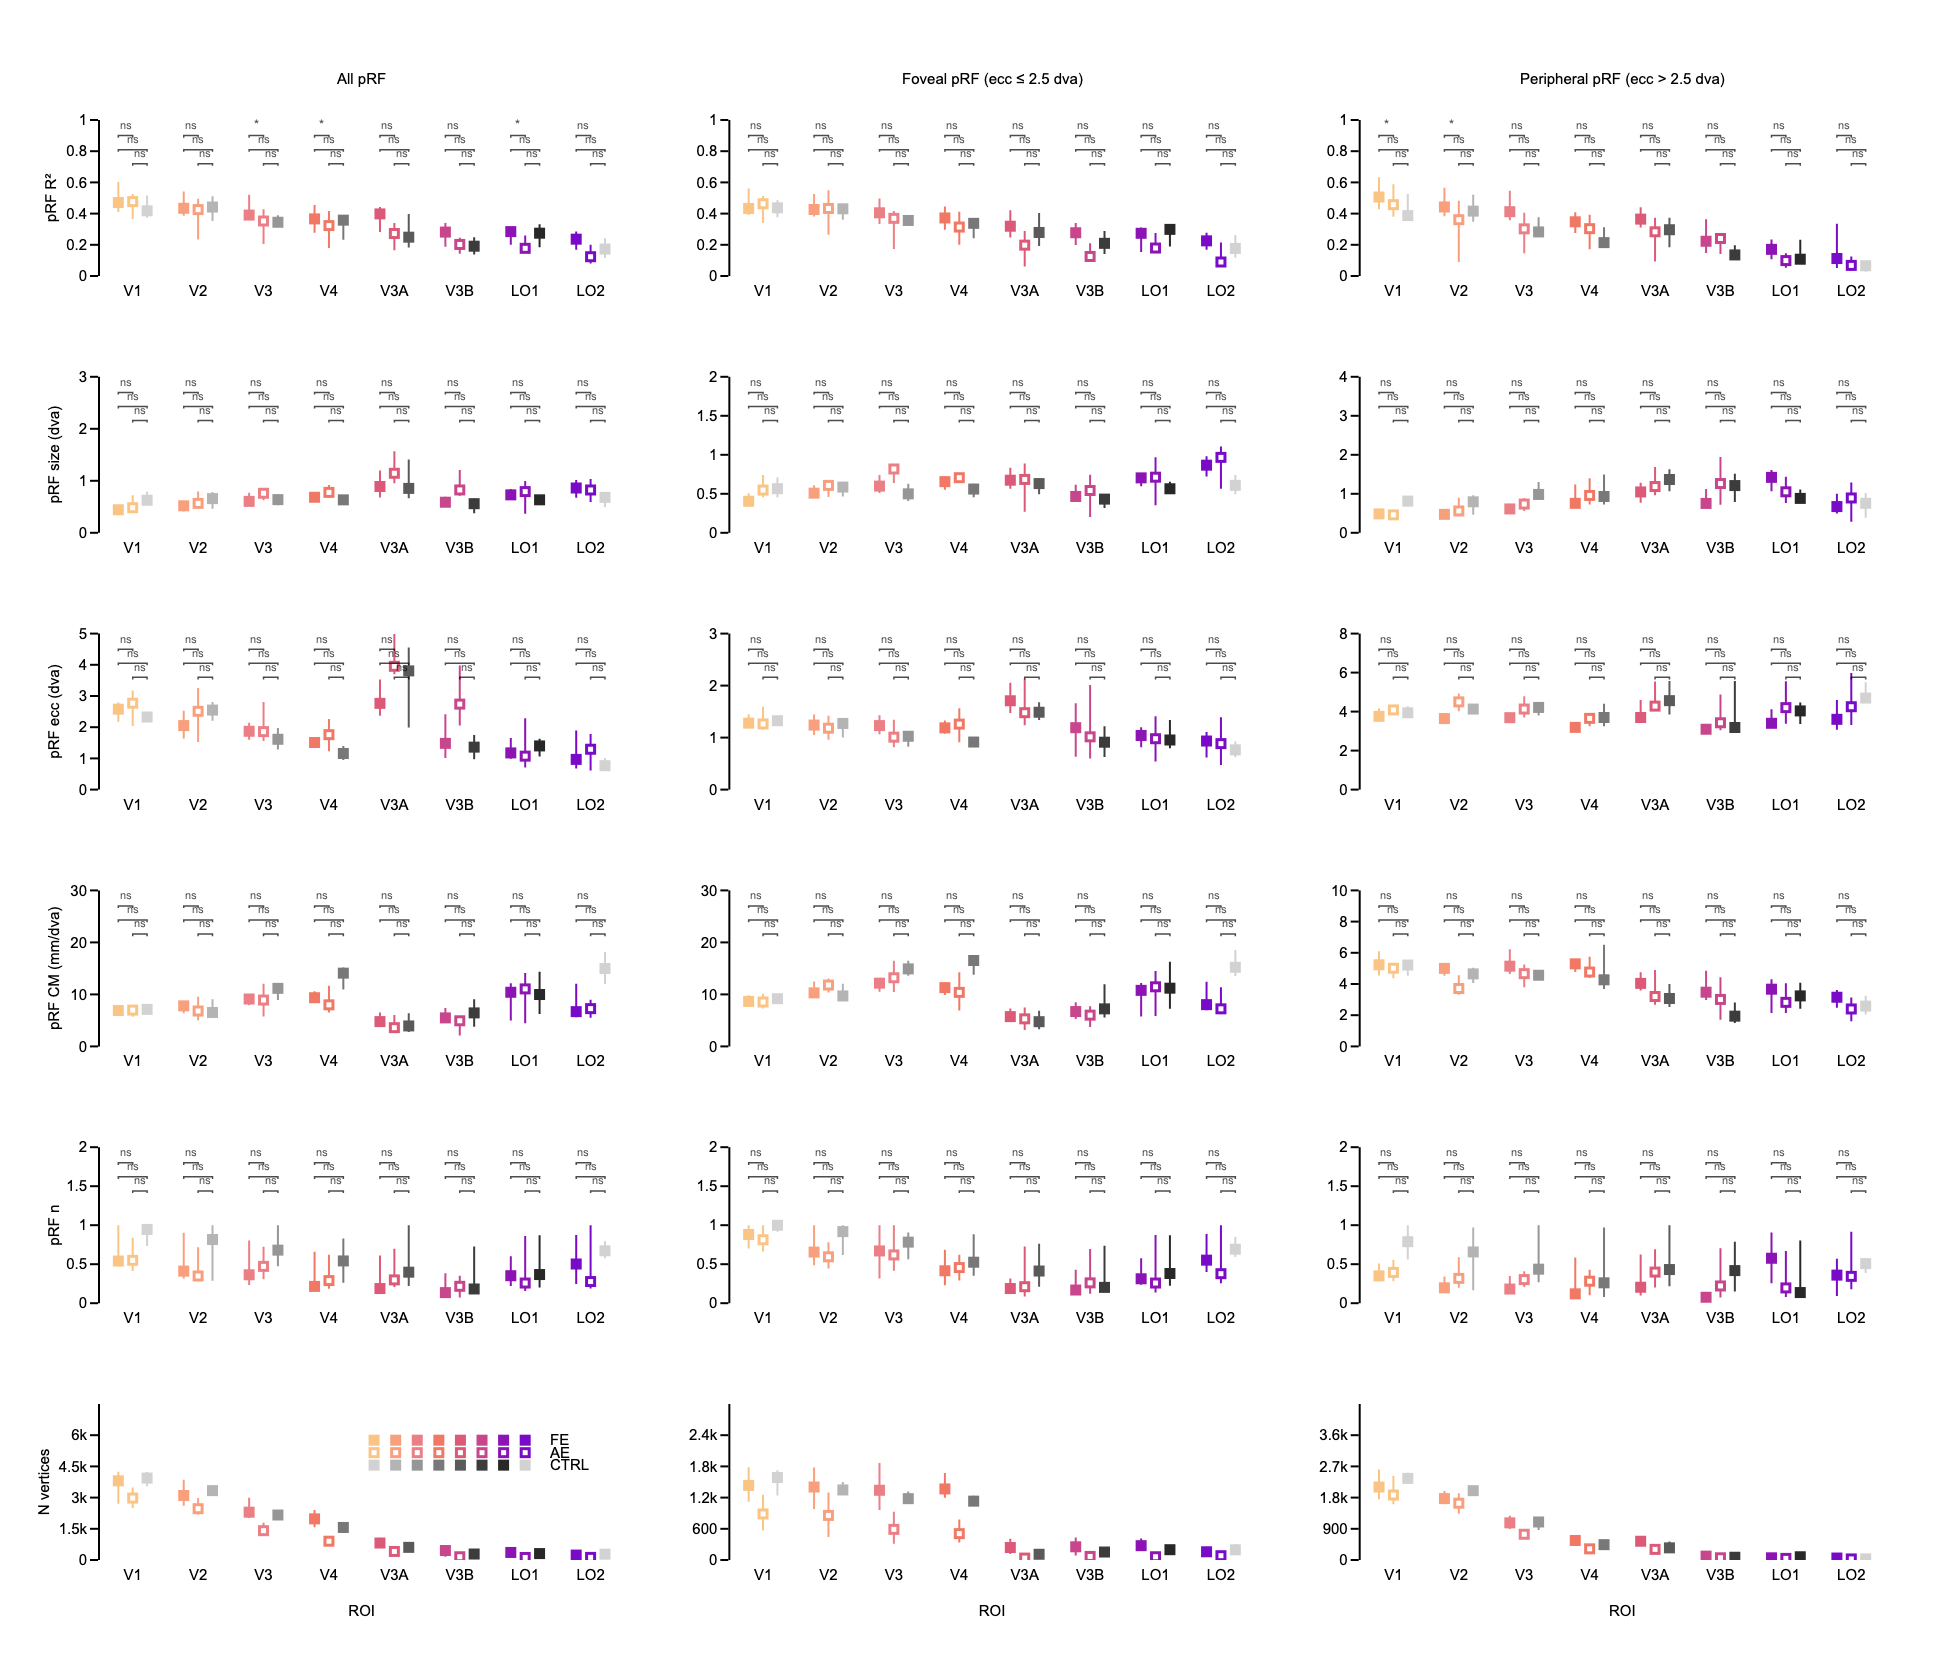

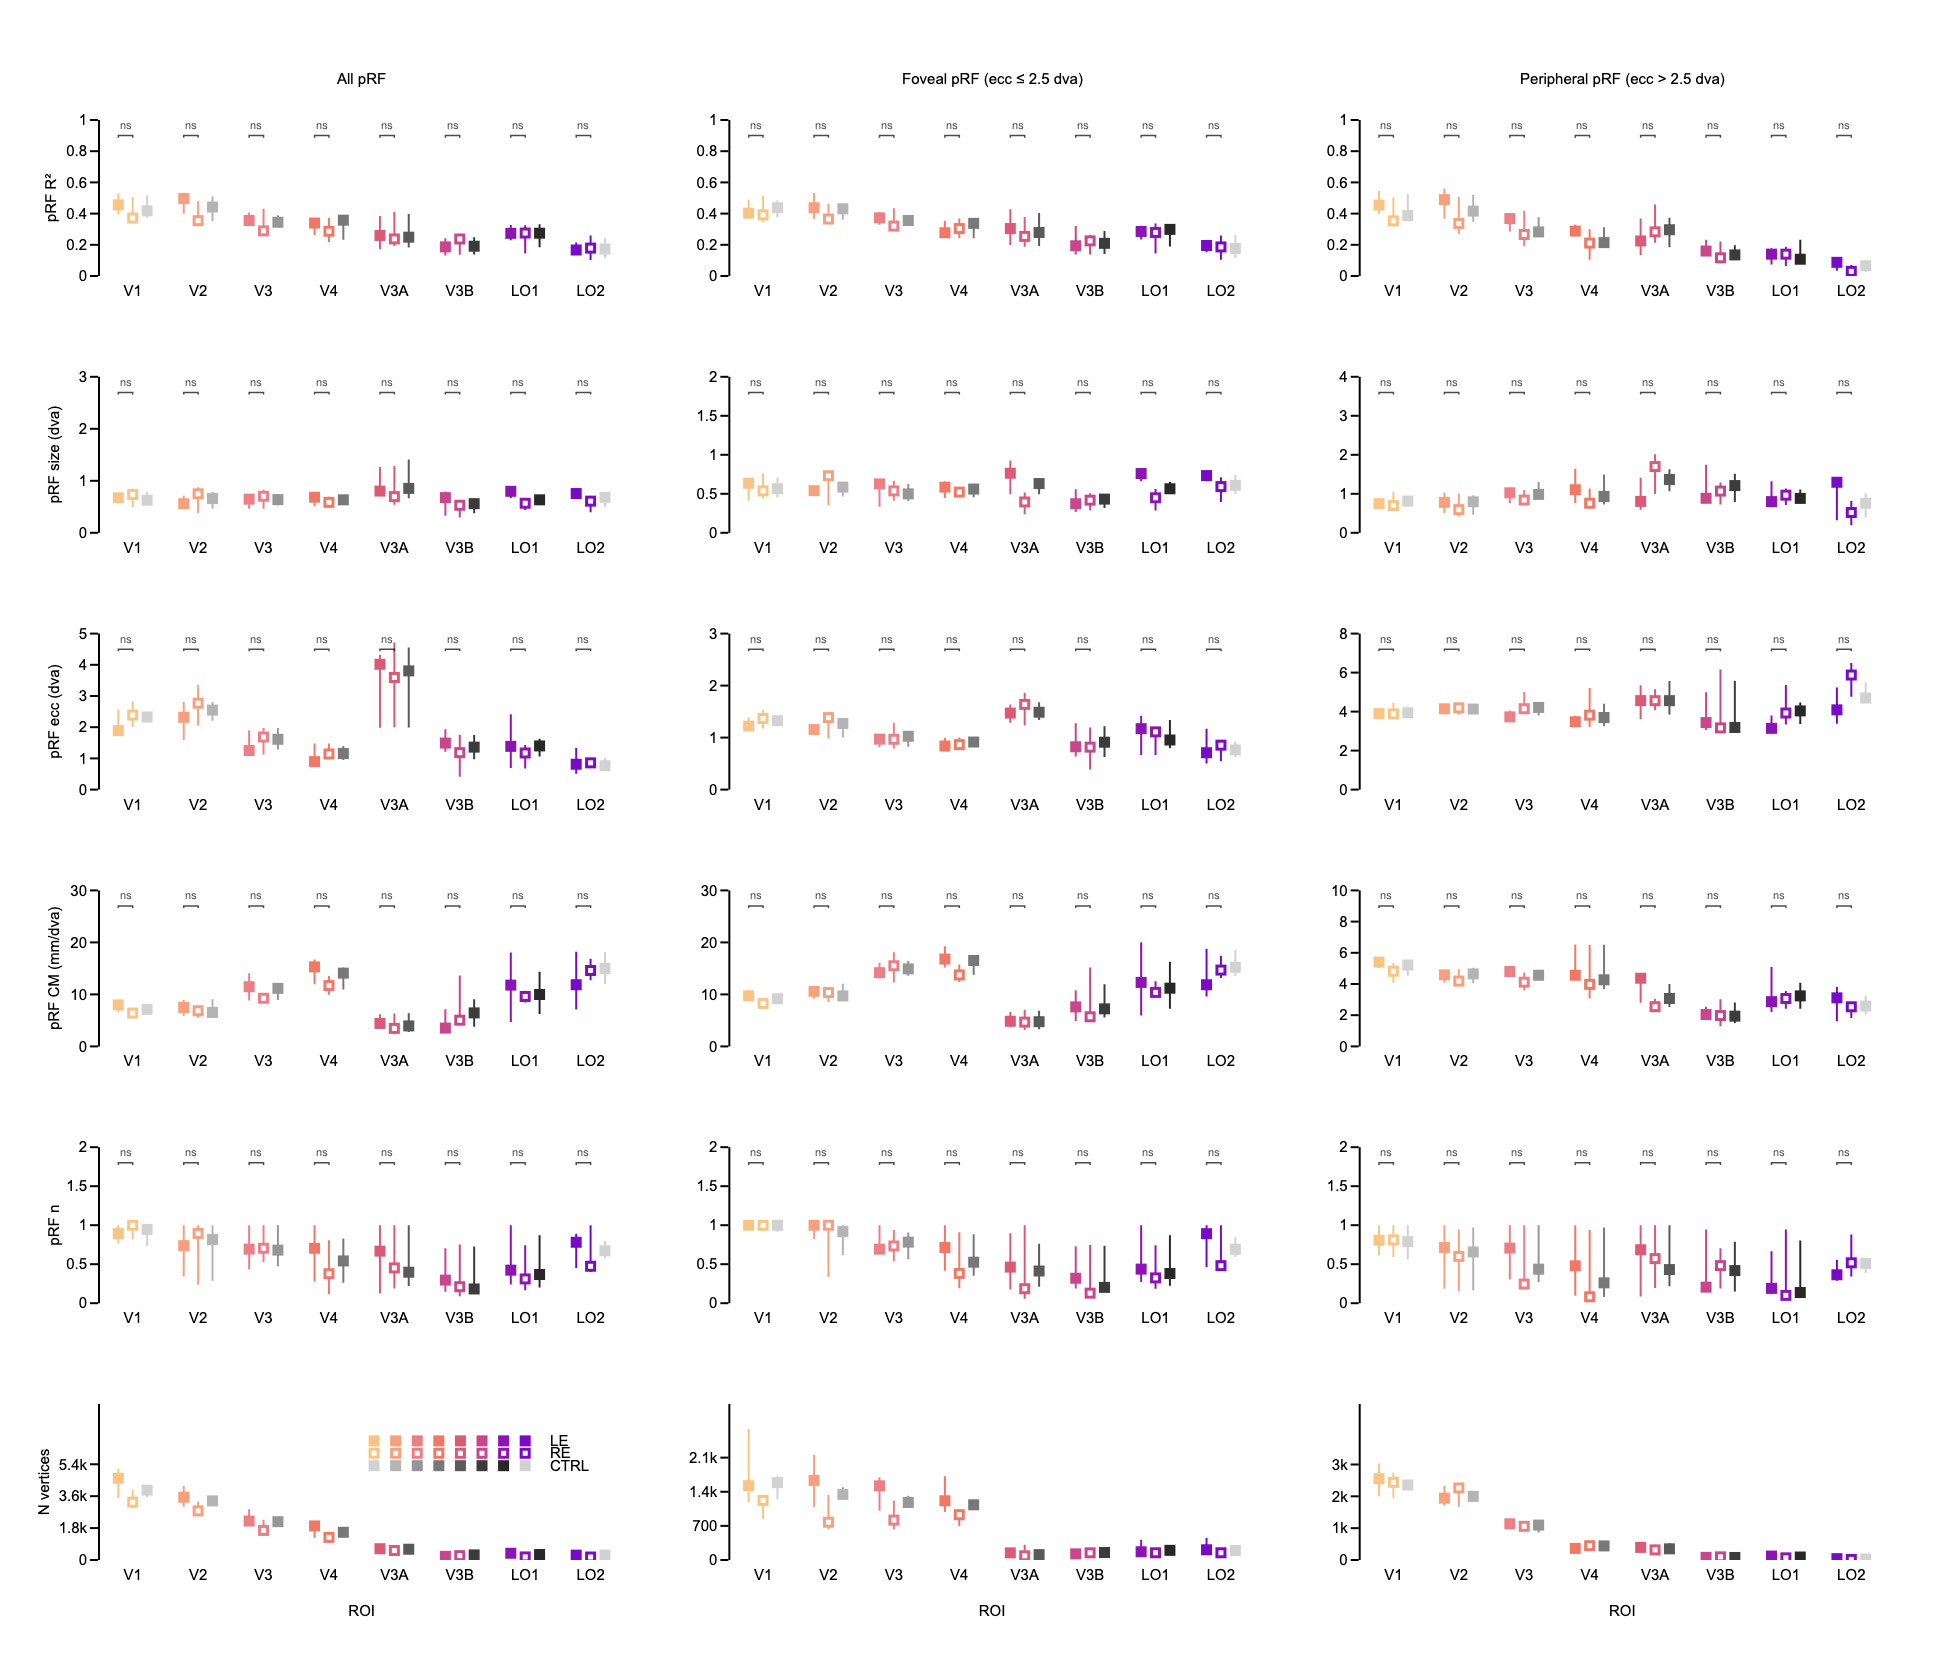

In [8]:
def figure_info_for(group):
    fi = analysis_info.copy()
    fi['rois'] = rois
    fi['subject_group'] = group
    return fi


for group in ['patient', 'control']:
    fig = ecc_comp_plot(df=ecc_grp[('od', group)], df_stats=ecc_stats[('od', group)], figure_info=figure_info_for(group),
                        eye_conditions=['AE-RE', 'FE-LE', 'CTRL'], show_stats=True)
    fig.show()
    fig.write_image('{}/prf_od-filter_group-{}_ecc-comp.pdf'.format(fig_dir, group))

### For comparison: ecc-comp without filter (PSC data, same as the prf_analysis scripts)

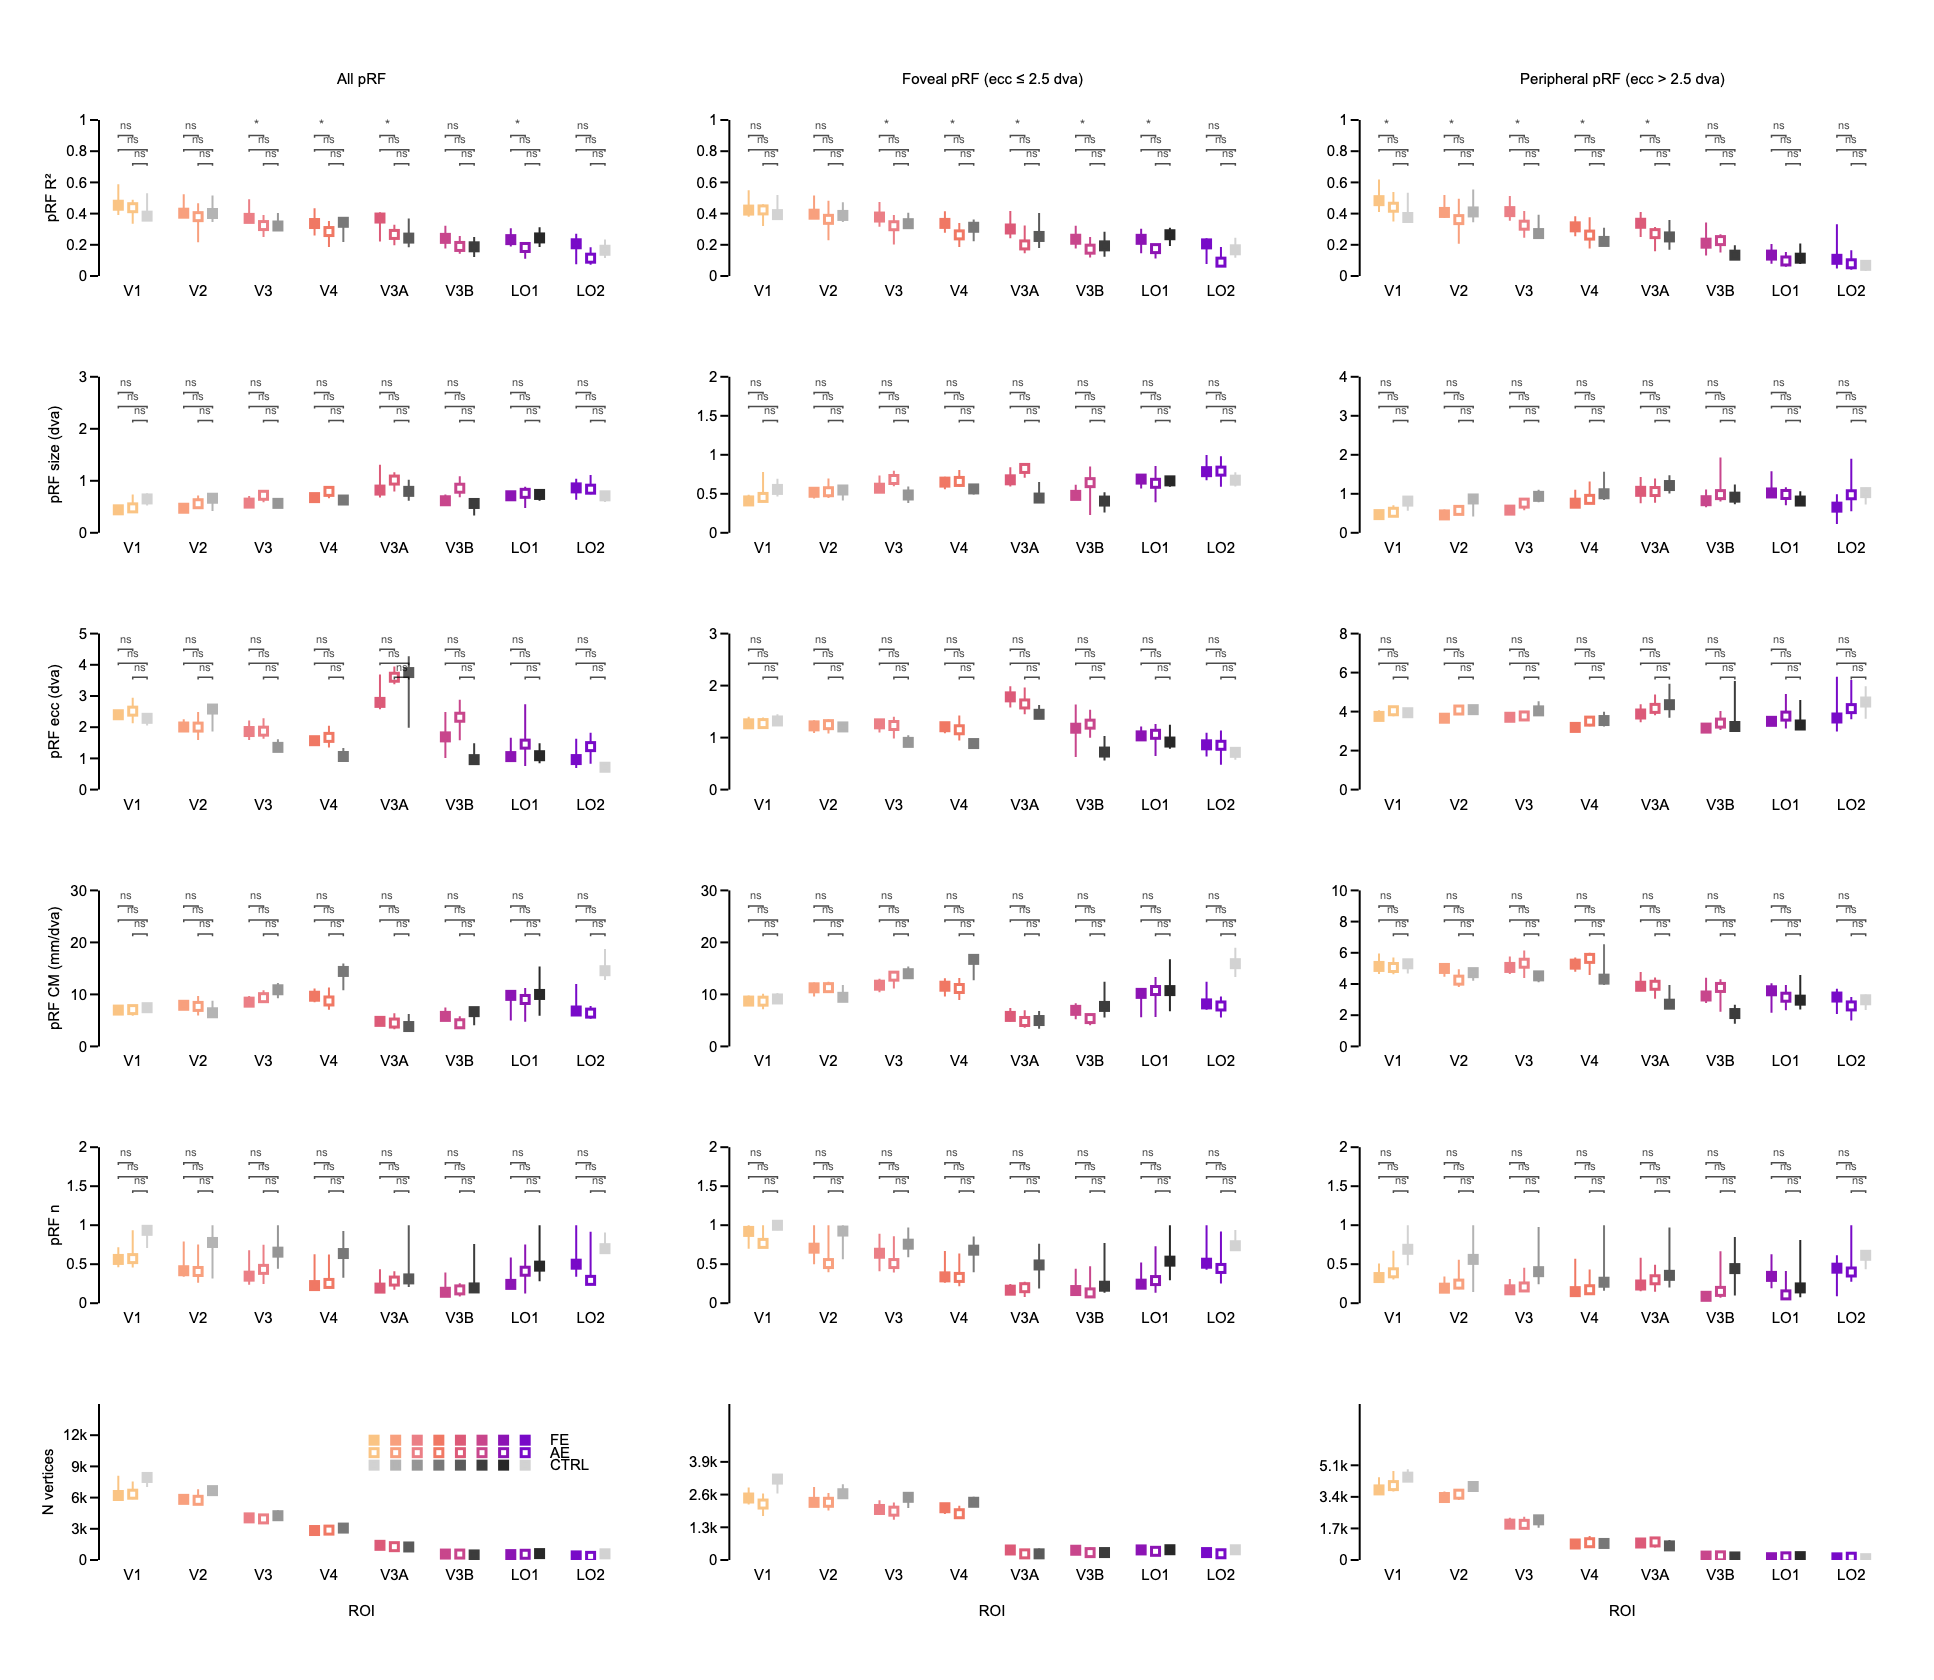

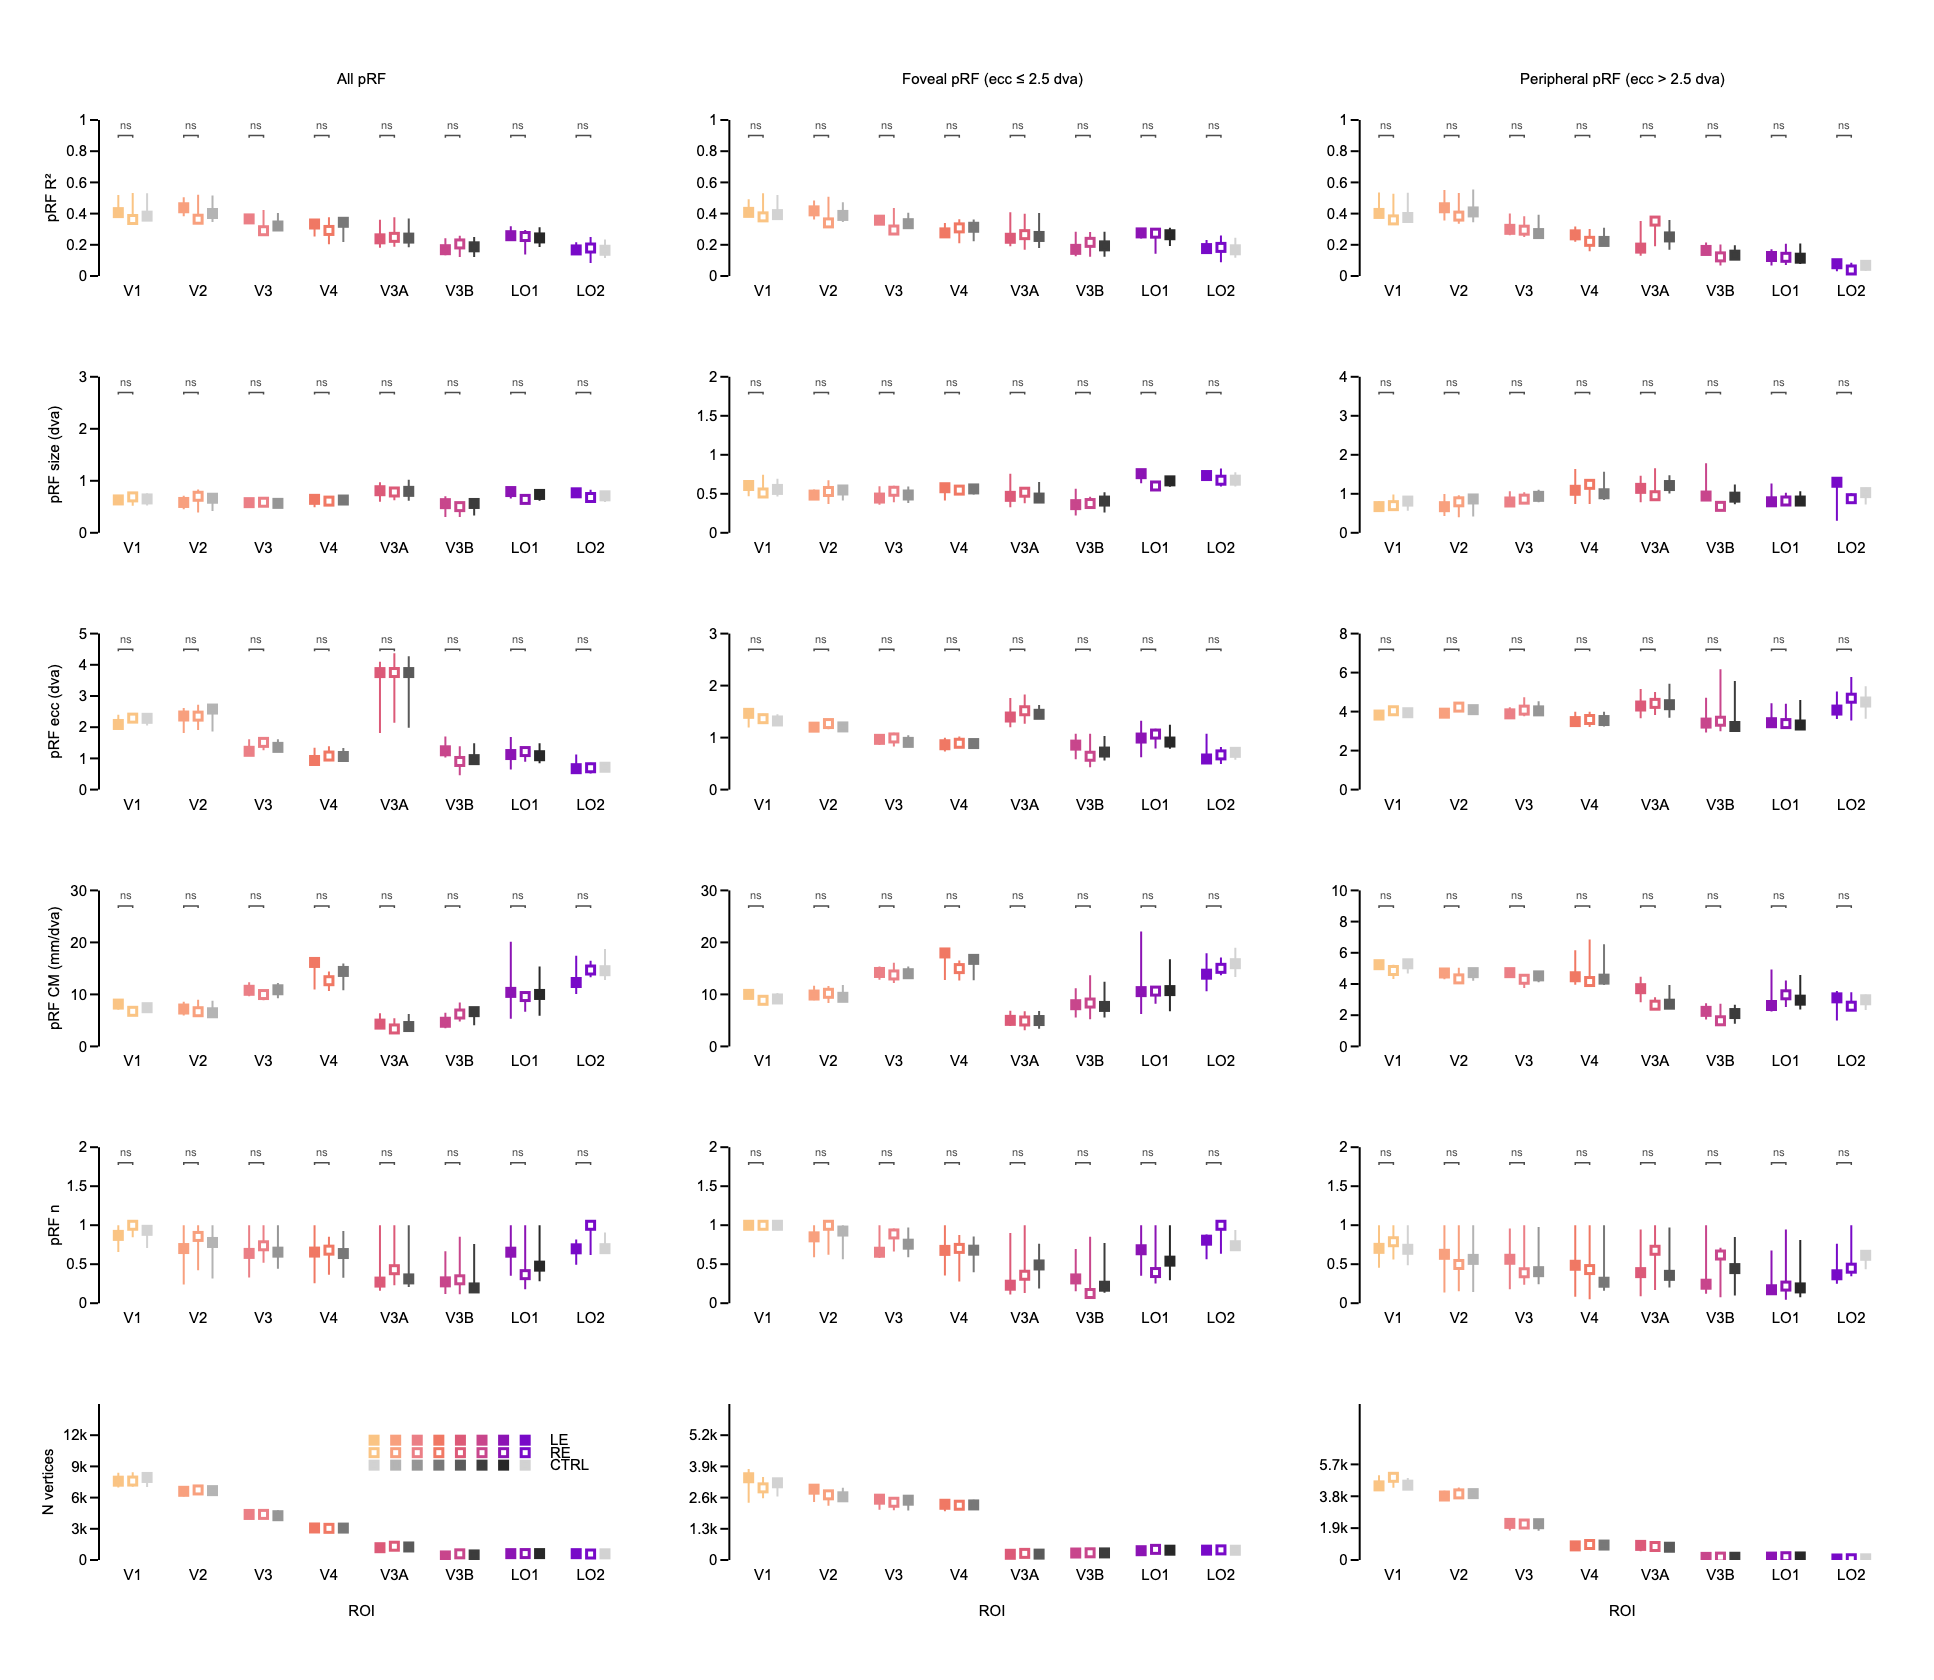


Patients, all eccentricities, filter = none
              prf_rsq_median             prf_size_median             prf_ecc_median             pcm_median_median              prf_n_median             n_vert_median                
eye_condition          AE-RE  CTRL FE-LE           AE-RE  CTRL FE-LE          AE-RE  CTRL FE-LE             AE-RE   CTRL FE-LE        AE-RE  CTRL FE-LE         AE-RE    CTRL   FE-LE
roi_mmp                                                                                                                                                                              
V1                      0.44  0.38  0.45            0.48  0.65  0.44           2.51  2.28  2.40              7.08   7.44  6.98         0.57  0.93  0.56        6327.0  7937.0  6202.0
V2                      0.38  0.40  0.40            0.56  0.66  0.47           2.00  2.58  2.01              7.69   6.47  7.91         0.41  0.78  0.42        5739.0  6670.5  5831.0
V3                      0.32  0.32  0.37     

In [9]:
for group in ['patient', 'control']:
    fig = ecc_comp_plot(df=ecc_grp[('none', group)], df_stats=ecc_stats[('none', group)], figure_info=figure_info_for(group),
                        eye_conditions=['AE-RE', 'FE-LE', 'CTRL'], show_stats=True)
    fig.show()
    fig.write_image('{}/prf_od-filter_group-{}_ecc-comp_no-filter.pdf'.format(fig_dir, group))

# Summary: patients, all eccentricities, median across subjects
cols = ['{}_median'.format(p) for p in params] + ['n_vert_median']
for filt in filters:
    g = ecc_grp[(filt, 'patient')]
    print('\nPatients, all eccentricities, filter = {}'.format(filt))
    print(g[g.ecc_category == 'all'].set_index([rois_to_plot, 'eye_condition'])[cols].unstack('eye_condition').reindex(rois).round(2).to_string())

## Figure 2 — eccentricity vs pRF size and pCM, OD filter

Same figure as `make_ecc_size_pcm_fig.py`: group median across subjects per eccentricity bin (patients with the CTRL curve of the controls).

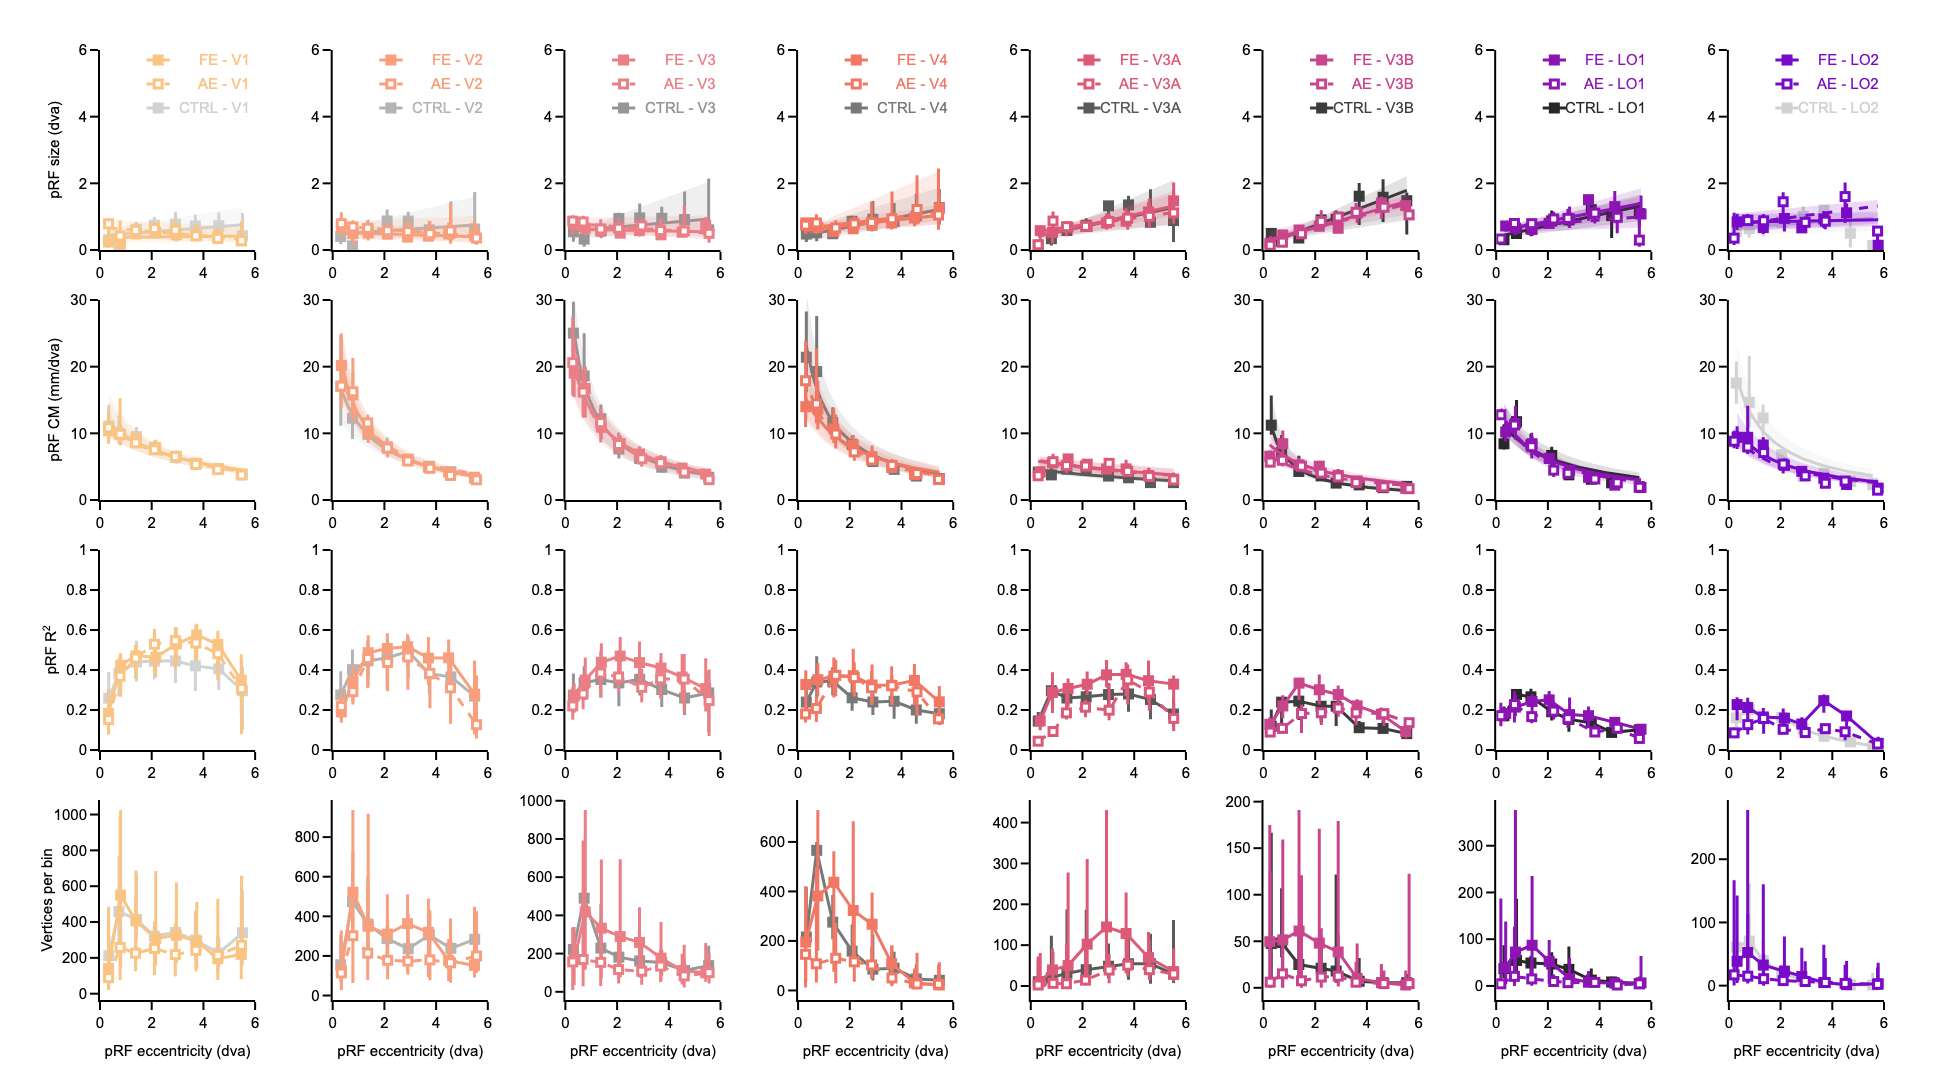

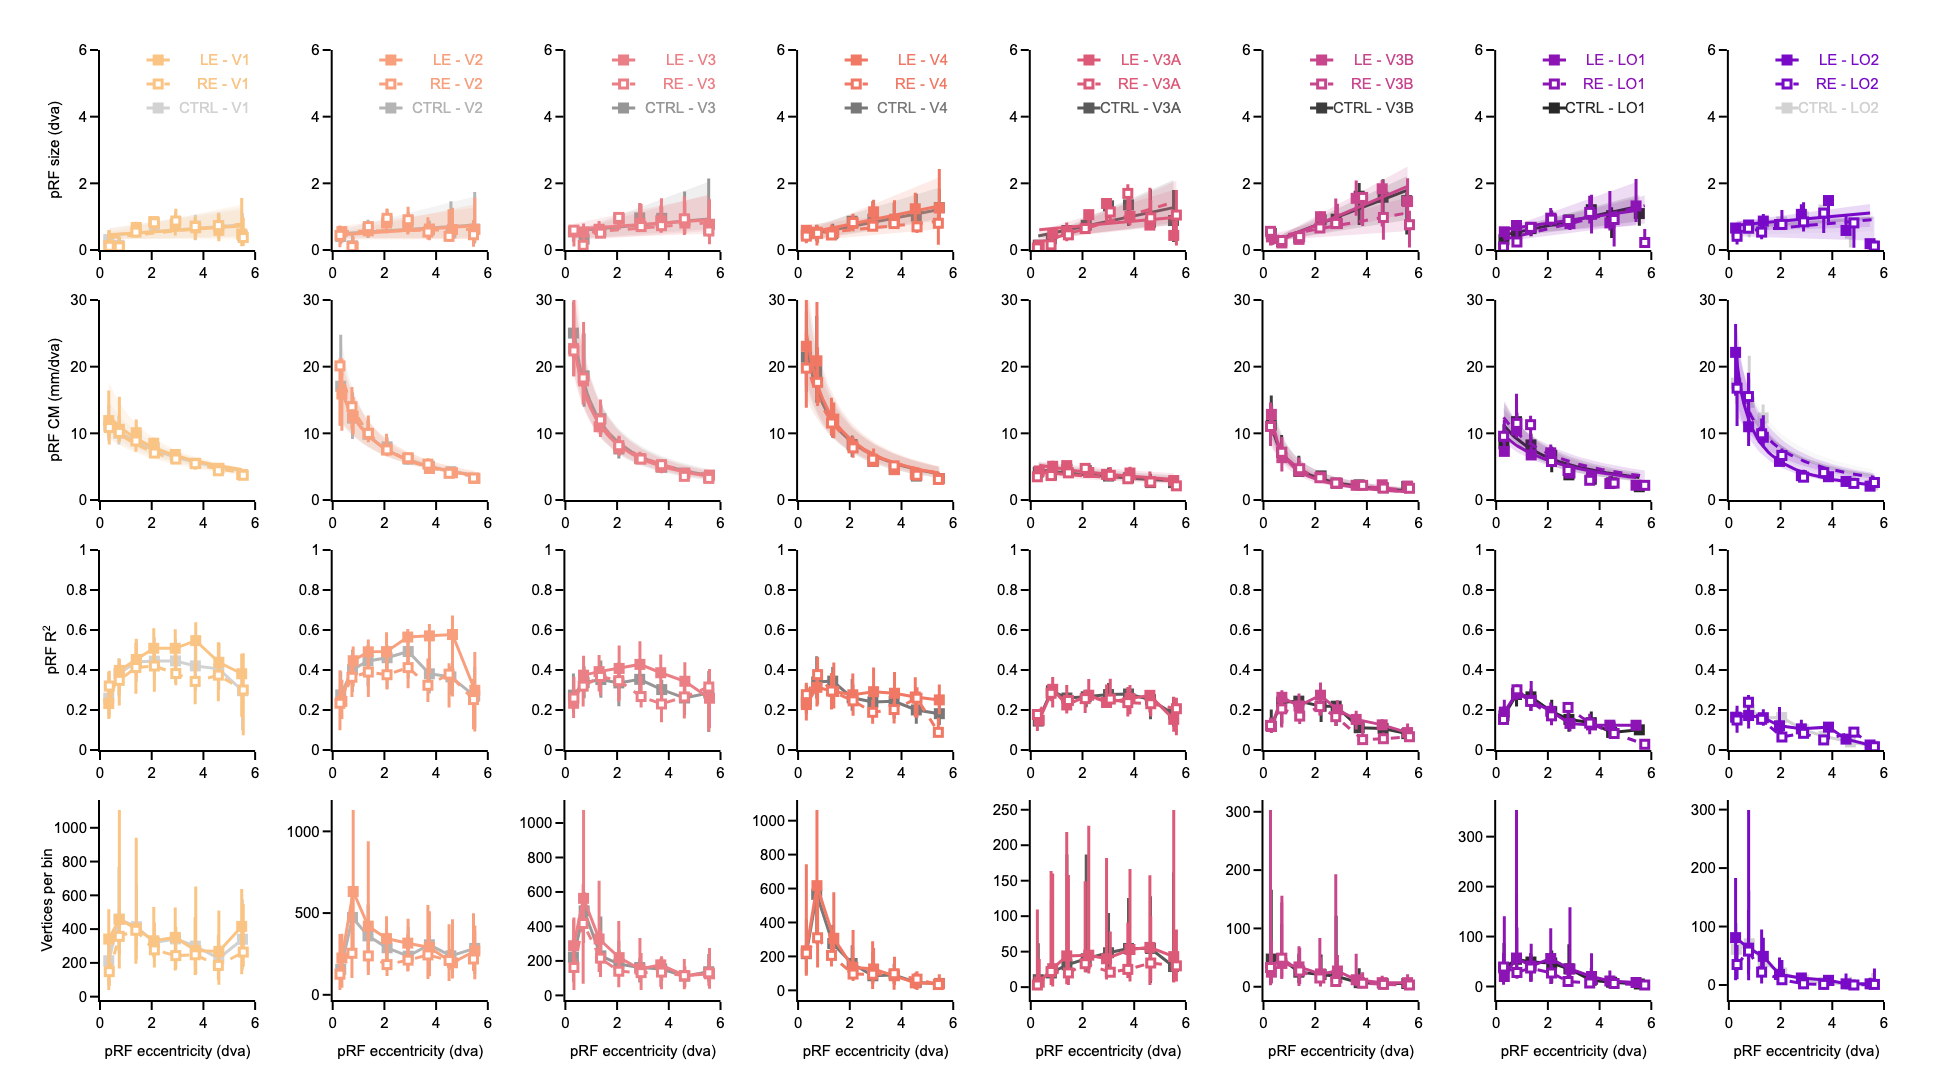

In [10]:
size_cols = [c for c in df_size.columns if c not in ['subject', 'subject_group', 'filter', 'roi', 'eye_condition', 'num_bins']]


def size_group(filt, group):
    d = df_size[(df_size['filter'] == filt) & (df_size.subject_group == group)]
    g = d.groupby(['roi', 'eye_condition', 'num_bins'], sort=False)[size_cols].median().reset_index()
    for col in ['prf_size_bins_median', 'prf_pcm_bins_median', '{}_bins_median'.format(rsq2use), 'n_vert_bins']:
        q = d.groupby(['roi', 'eye_condition', 'num_bins'], sort=False)[col]
        g['{}_ci_lower'.format(col)] = q.quantile(0.025).values
        g['{}_ci_upper'.format(col)] = q.quantile(0.975).values
    return g


for group in ['patient', 'control']:
    g = size_group('od', group)
    df_ctrl = size_group('od', 'control').query("eye_condition == 'CTRL'") if group == 'patient' else None
    if group == 'patient':
        g = g[g.eye_condition.isin(['AE-RE', 'FE-LE'])]
    fig = eyes_ecc_size_pcm_plot(df=g, figure_info=figure_info_for(group), rsq2use=rsq2use, df_ctrl=df_ctrl)
    fig.show()
    fig.write_image('{}/prf_od-filter_group-{}_ecc-size-pcm.pdf'.format(fig_dir, group))

## Figure 3 — active vertices, OD filter

Same figure as `make_active_vert_fig.py`: per ROI, all vertices of the ROI (background bar) and the vertices with a significant fit (FDR 0.05 / 0.01) **that prefer this eye** (median across subjects; % = proportion of the ROI). Table: tests on the proportion of active vertices (FDR 0.05).

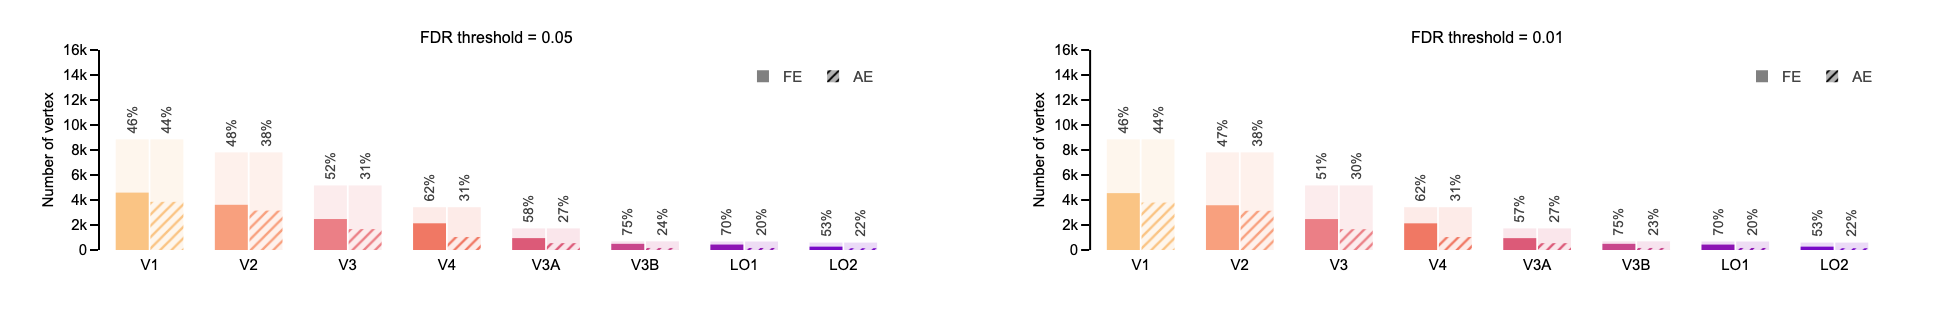

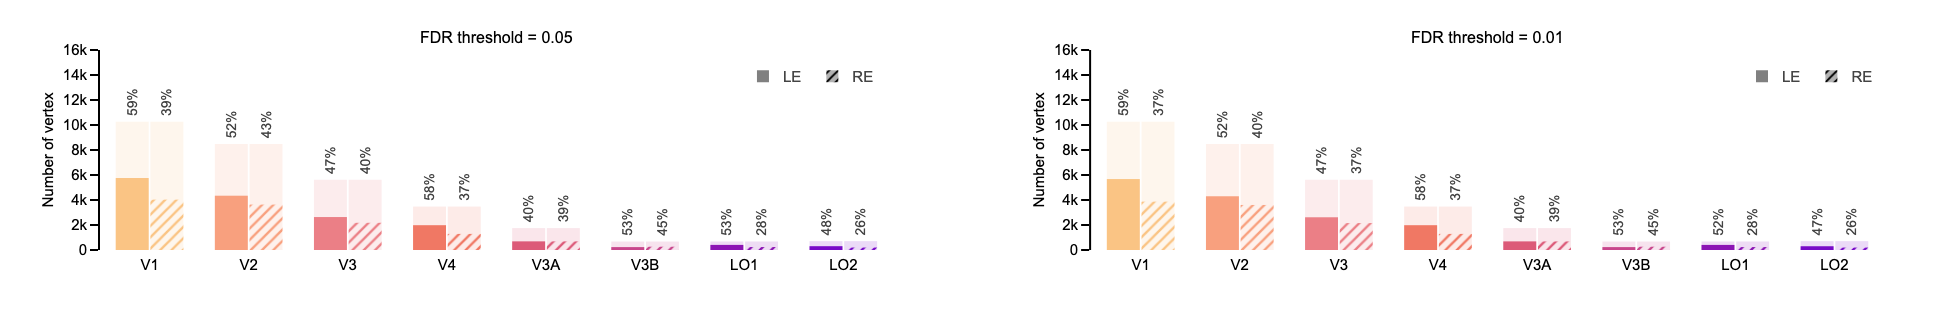


Active vertices (proportion of the ROI, FDR 0.05), group patient, filter none
roi_mmp cond_A cond_B  median_A  median_B  p_unc  p_corr stars
     V1  FE-LE  AE-RE     0.974     0.966  0.424   0.948    ns
     V1  FE-LE   CTRL     0.974     0.981  0.384   0.948    ns
     V1  AE-RE   CTRL     0.966     0.981  0.340   0.948    ns
     V2  FE-LE  AE-RE     0.970     0.961  0.970   1.000    ns
     V2  FE-LE   CTRL     0.970     0.969  0.711   0.948    ns
     V2  AE-RE   CTRL     0.961     0.969  0.536   0.948    ns
     V3  FE-LE  AE-RE     0.964     0.934  0.622   0.948    ns
     V3  FE-LE   CTRL     0.964     0.949  1.000   1.000    ns
     V3  AE-RE   CTRL     0.934     0.949  0.711   0.948    ns
     V4  FE-LE  AE-RE     0.962     0.942  0.910   1.000    ns
     V4  FE-LE   CTRL     0.962     0.974  0.340   0.948    ns
     V4  AE-RE   CTRL     0.942     0.974  0.196   0.948    ns
    V3A  FE-LE  AE-RE     0.971     0.961  0.470   0.948    ns
    V3A  FE-LE   CTRL     0.971     0.8

In [11]:
act_cols = ['n_vert_tot', 'n_vert_corr_pvalue_5pt', 'n_vert_corr_pvalue_1pt', 'ratio_5pt', 'ratio_1pt']
for group in ['patient', 'control']:
    d = df_act[(df_act['filter'] == 'od') & (df_act.subject_group == group)]
    g = d.groupby([rois_to_plot, 'eye_condition'], sort=False)[act_cols].median().reset_index()
    for col in ['ratio_5pt', 'ratio_1pt']:
        q = d.groupby([rois_to_plot, 'eye_condition'], sort=False)[col]
        g['{}_ci_upper'.format(col)] = q.quantile(0.975).values
        g['{}_ci_lower'.format(col)] = q.quantile(0.025).values
    fig = eyes_active_vert_plot(df=g, figure_info=figure_info_for(group), format_='fsnative')
    fig.show()
    fig.write_image('{}/prf_od-filter_group-{}_active-vert.pdf'.format(fig_dir, group))

for group in ['patient', 'control']:
    for filt in filters:
        print('\nActive vertices (proportion of the ROI, FDR 0.05), group {}, filter {}'.format(group, filt))
        print(act_stats[(filt, group)].round(3).to_string(index=False))

## Where are the OD-filtered vertices?

With the filter, each eye is described on its own vertices. If the AE-preferring vertices of the amblyopes are, for example, more peripheral than the FE-preferring ones, a difference of pRF size or pCM between AE and FE can come from this difference of position. Check: per subject and ROI, median eccentricity (R²-weighted, thresholded vertices) and number of the vertices kept for each eye. Paired Wilcoxon AE vs FE on the eccentricity, FDR over the ROIs.

In [12]:
rows = []
for roi in rois:
    d = df_ecc[(df_ecc['filter'] == 'od') & (df_ecc.subject_group == 'patient') & (df_ecc.ecc_category == 'all') & (df_ecc[rois_to_plot] == roi)]
    piv = d.pivot(index='subject', columns='eye_condition', values='prf_ecc_median').dropna()
    pn = d.pivot(index='subject', columns='eye_condition', values='n_vert')
    rows.append({rois_to_plot: roi, 'ecc_AE': piv['AE-RE'].median(), 'ecc_FE': piv['FE-LE'].median(),
                 'p': stats.wilcoxon(piv['AE-RE'], piv['FE-LE']).pvalue if len(piv) > 1 else np.nan,
                 'n_vert_AE': pn['AE-RE'].median(), 'n_vert_FE': pn['FE-LE'].median()})
pos = pd.DataFrame(rows)
pos['p_fdr'] = bh_fdr(pos.p)
print('Amblyopes, OD filter: median eccentricity and number of thresholded vertices of the vertices kept for each eye')
print(pos.round(3).to_string(index=False))

Amblyopes, OD filter: median eccentricity and number of thresholded vertices of the vertices kept for each eye
roi_mmp  ecc_AE  ecc_FE     p  n_vert_AE  n_vert_FE  p_fdr
     V1   2.770   2.578 0.622     2977.0     3806.0  0.829
     V2   2.510   2.052 0.301     2466.0     3102.0  0.752
     V3   1.858   1.869 0.910     1410.0     2298.5  0.910
     V4   1.761   1.509 0.380      903.5     1978.0  0.752
    V3A   3.952   2.764 0.021      411.0      816.0  0.084
    V3B   2.740   1.482 0.009      156.0      456.0  0.074
    LO1   1.072   1.176 0.850      121.5      362.5  0.910
    LO2   1.293   0.968 0.470      125.5      236.0  0.752
